# Laboratorium 5 — Warstwy splotowe: co „widzi" sieć

**Cel:** zrozumieć operację splotu i jej parametry. Sprawdzimy wzór na wymiary wyjścia, zastosujemy ręczne jądra do obrazu, zbadamy wpływ stride/padding/dilation i podejrzymy wyuczone filtry oraz mapy cech gotowej sieci.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 0. Instalacja zależności

In [ ]:
!pip install torch torchvision matplotlib

## Import bibliotek i wybór urządzenia

In [ ]:
import urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.14.1+cu130 | urządzenie: cuda


## 1. Wzór na wymiary wyjścia

$$\text{out} = \left\lfloor \frac{\text{in} + 2p - d(k-1) - 1}{s} + 1 \right\rfloor$$

Porównajmy wynik wzoru z faktycznym wyjściem `nn.Conv2d` dla różnych parametrów.

In [ ]:
def out_dim(in_size, k, s=1, p=0, d=1):
    return (in_size + 2*p - d*(k-1) - 1)//s + 1

IN = 32
configs = [
    dict(k=3, s=1, p=1, d=1),
    dict(k=3, s=2, p=1, d=1),
    dict(k=5, s=1, p=2, d=1),
    dict(k=3, s=1, p=2, d=2),
    dict(k=7, s=2, p=3, d=1),
]
print(f"in={IN}")
print(f"{'k':>2} {'s':>2} {'p':>2} {'d':>2} | {'wzór':>5} {'Conv2d':>7}")
x = torch.randn(1, 3, IN, IN)
for c in configs:
    conv = nn.Conv2d(3, 8, kernel_size=c['k'], stride=c['s'], padding=c['p'], dilation=c['d'])
    real = conv(x).shape[-1]
    formula = out_dim(IN, **c)
    ok = '✓' if real == formula else '✗'
    print(f"{c['k']:>2} {c['s']:>2} {c['p']:>2} {c['d']:>2} | {formula:>5} {real:>7}  {ok}")

in=32
 k  s  p  d |  wzór  Conv2d
 3  1  1  1 |    32      32  ✓
 3  2  1  1 |    16      16  ✓
 5  1  2  1 |    32      32  ✓
 3  1  2  2 |    32      32  ✓
 7  2  3  1 |    16      16  ✓


## 2. Wczytaj obraz

Użyto własnego zdjęcia ze swojego repozytorium

Wczytano zdjęcie.


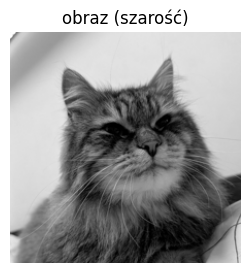

In [ ]:
try:
    urllib.request.urlretrieve("https://raw.githubusercontent.com/wik990s/Rozpoznawanie_Obiekt-w_WS/refs/heads/main/pliki_rozpoznawanie_obiektow/wlasne_zdj_lab5.jpg", "img.jpg")
    pil = Image.open("img.jpg").convert("RGB").resize((224, 224))
    print("Wczytano zdjęcie.")
except Exception as e:
    print("Brak sieci, generuję obraz syntetyczny:", e)
    yy, xx = np.mgrid[0:224, 0:224]
    arr = ((np.sin(xx/12.0)*0.5+0.5)*255).astype(np.uint8)
    arr[60:160, 60:160] = 240  # jasny kwadrat = wyraźne krawędzie
    pil = Image.fromarray(np.stack([arr]*3, -1))

rgb = torch.from_numpy(np.array(pil)).float().permute(2,0,1).unsqueeze(0) / 255.0  # [1,3,H,W]
gray = rgb.mean(1, keepdim=True)  # [1,1,H,W]
plt.figure(figsize=(3,3)); plt.imshow(gray[0,0], cmap="gray"); plt.axis("off"); plt.title("obraz (szarość)"); plt.show()

## 3. Ręczne jądra

Zdefiniujmy klasyczne jądra i zastosujmy je przez `F.conv2d` (padding zachowuje rozmiar). Krawędzie Sobela łączymy w magnitudę.

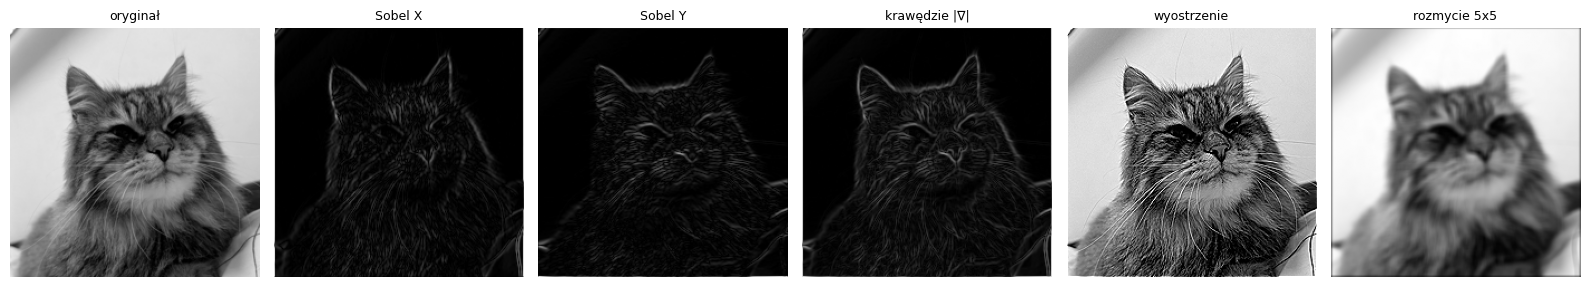

In [ ]:
def kernel(t):
    return torch.tensor(t, dtype=torch.float32).view(1,1,*np.array(t).shape)

sobel_x = kernel([[-1,0,1],[-2,0,2],[-1,0,1]])
sobel_y = kernel([[-1,-2,-1],[0,0,0],[1,2,1]])
sharpen = kernel([[0,-1,0],[-1,5,-1],[0,-1,0]])
blur = torch.ones(1,1,5,5)/25.0

gx = F.conv2d(gray, sobel_x, padding=1)
gy = F.conv2d(gray, sobel_y, padding=1)
edges = (gx**2 + gy**2).sqrt()
results = {
    "oryginał": gray,
    "Sobel X": gx.abs(),
    "Sobel Y": gy.abs(),
    "krawędzie |∇|": edges,
    "wyostrzenie": F.conv2d(gray, sharpen, padding=1).clamp(0,1),
    "rozmycie 5x5": F.conv2d(gray, blur, padding=2),
}
fig, axes = plt.subplots(1, len(results), figsize=(16, 3))
for ax, (name, out) in zip(axes, results.items()):
    m = out[0,0].detach()
    ax.imshow(m, cmap="gray"); ax.set_title(name, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Wpływ stride, padding i dilation

Ten sam detektor krawędzi z różnymi ustawieniami.


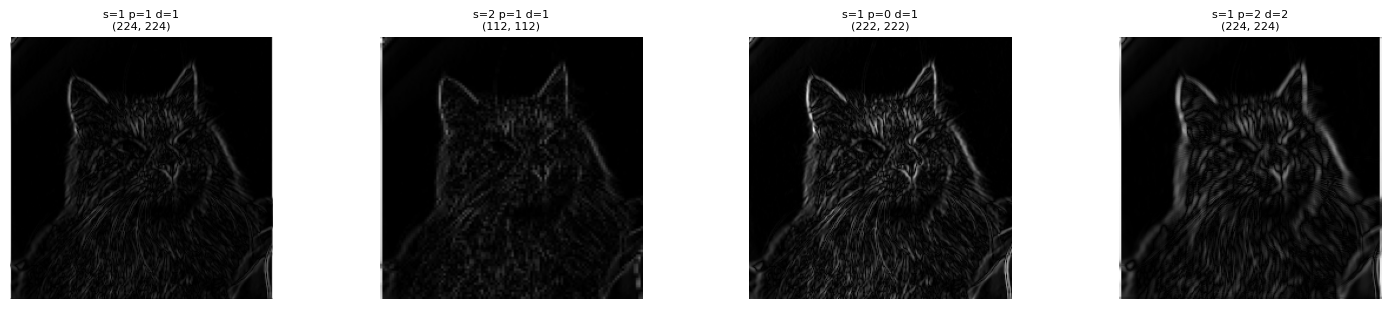

In [ ]:
settings = [
    dict(stride=1, padding=1, dilation=1),  # zachowuje rozmiar
    dict(stride=2, padding=1, dilation=1),  # zmniejsza ~2x
    dict(stride=1, padding=0, dilation=1),  # brak paddingu
    dict(stride=1, padding=2, dilation=2),  # dilation - większe pole
]
fig, axes = plt.subplots(1, len(settings), figsize=(15, 3.2))
for ax, s in zip(axes, settings):
    out = F.conv2d(gray, sobel_x, **s)
    ax.imshow(out[0,0].abs().detach(), cmap="gray")
    ax.set_title(f"s={s['stride']} p={s['padding']} d={s['dilation']}\n{tuple(out.shape[-2:])}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5. Filtry i mapy cech wyuczonej sieci

Podejrzyjmy filtry **pierwszej** warstwy pretrenowanego ResNet-18 (64 filtry 7×7×3) oraz mapy cech dla naszego obrazu. Filtry pierwszej warstwy przypominają detektory krawędzi i plam koloru.

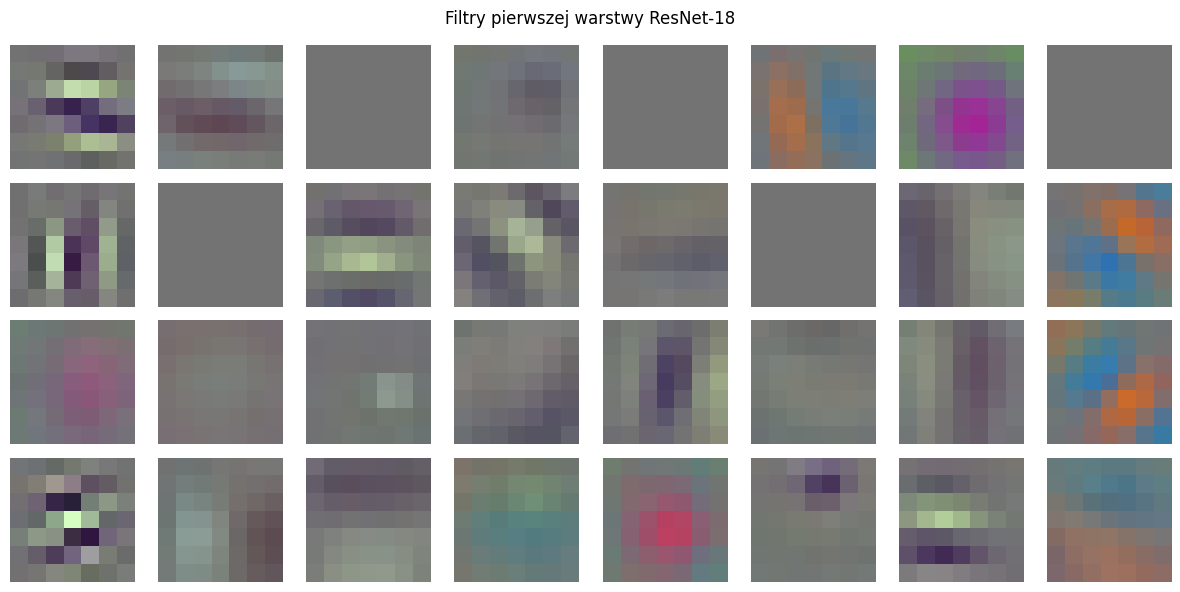

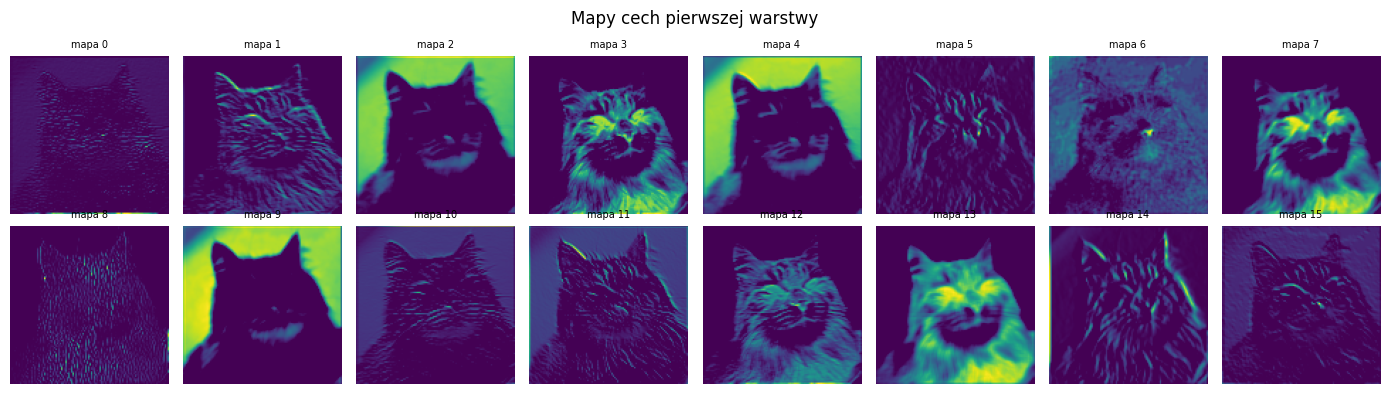

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()

# 5a. wagi pierwszej warstwy jako obrazki RGB
W = model.conv1.weight.data.clone().cpu()  # [64,3,7,7]
Wn = (W - W.min()) / (W.max() - W.min())
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(Wn[i].permute(1,2,0)); ax.axis("off")
fig.suptitle("Filtry pierwszej warstwy ResNet-18"); plt.tight_layout(); plt.show()

# 5b. mapy cech dla naszego obrazu
preprocess = weights.transforms()
x = preprocess(pil).unsqueeze(0).to(device)
with torch.no_grad():
    fmaps = torch.relu(model.conv1(x))[0].cpu()  # [64, H, W]
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmaps[i], cmap="viridis"); ax.set_title(f"mapa {i}", fontsize=7); ax.axis("off")
fig.suptitle("Mapy cech pierwszej warstwy"); plt.tight_layout(); plt.show()

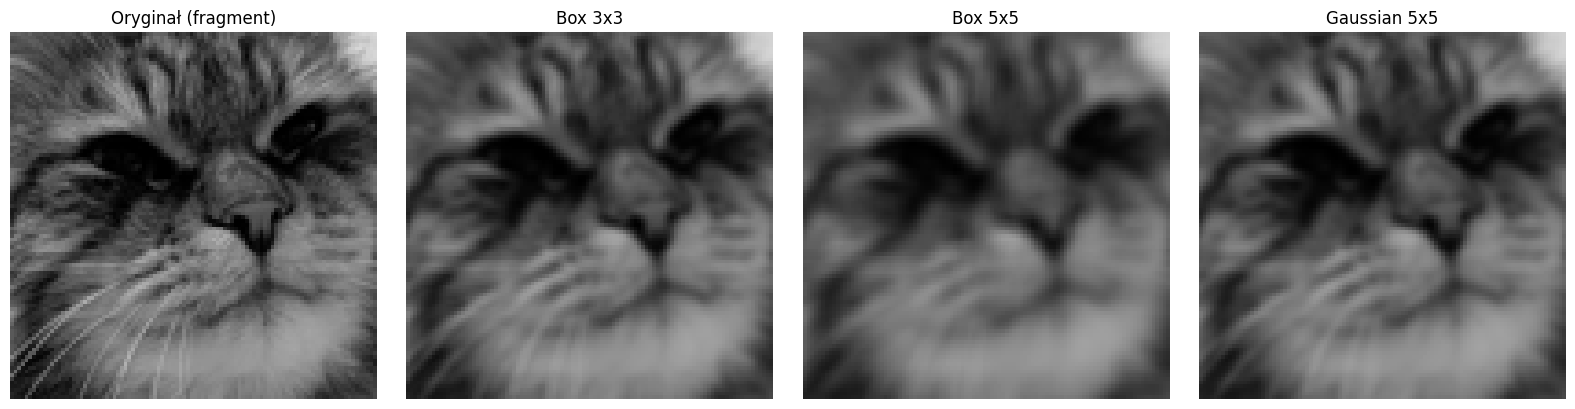

In [ ]:
box3 = torch.ones(1,1,3,3)/9.0
g_wektor = torch.tensor([1.,4.,6.,4.,1.])
gaussian5 = (g_wektor.view(-1,1) @ g_wektor.view(1,-1)).view(1,1,5,5)/256.0
out_box3 = F.conv2d(gray, box3, padding=1)
out_box5 = F.conv2d(gray, blur, padding=2)
out_gauss5 = F.conv2d(gray, gaussian5, padding=2)

y1, y2 = 60, 160
x1, x2 = 70, 170
frag_o = gray[0,0,y1:y2,x1:x2].detach()
frag_box3 = out_box3[0,0,y1:y2,x1:x2].detach()
frag_box5 = out_box5[0,0,y1:y2,x1:x2].detach()
frag_gauss5 = out_gauss5[0,0,y1:y2,x1:x2].detach()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
images = [frag_o, frag_box3, frag_box5, frag_gauss5]
titles = ["Oryginał (fragment)", "Box 3x3", "Box 5x5", "Gaussian 5x5"]
for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Zakres dodatkowy

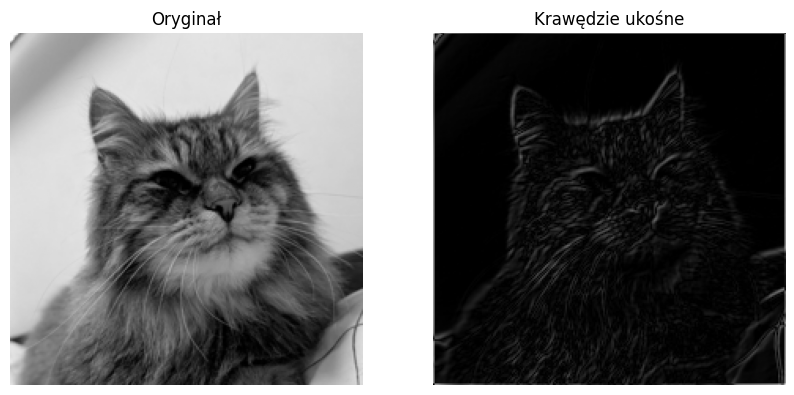

In [ ]:
#jądro wykrywające krawędzie pod kątem 45 stopni
diag_k = kernel([[1,1,0],[1,0,-1],[0,-1,-1]])
diag_k = F.conv2d(gray, diag_k, padding=1)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(gray[0, 0].detach(), cmap='gray')
plt.title("Oryginał")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(diag_k.abs()[0, 0].detach(), cmap='gray')
plt.title("Krawędzie ukośne")
plt.axis("off")
plt.show()

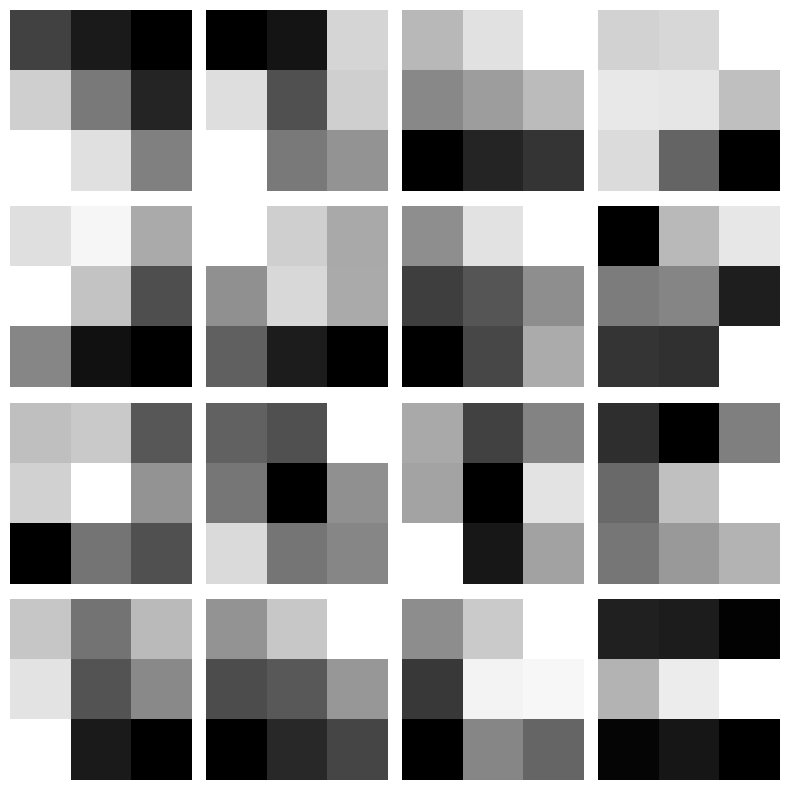

In [ ]:
#wagi z głębszej warstwy
wg = model.layer2[0].conv1.weight.data.clone().cpu()
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
  wgs = wg[i, 0]
  wng = (wgs - wgs.min()) / (wgs.max() - wgs.min() + 1e-8)
  ax.imshow(wng, cmap='gray'); ax.axis("off")
plt.tight_layout()
plt.show()